# 06 — Sequence models and signal hypothesis testing

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What this notebook does**

1. **Sequence models for detection.** A **Transformer encoder** on patches (tokens) of the whitened series is compared with the 1-D CNN of notebook 05 and with a bidirectional **GRU** (cheap recurrent baseline) that uses the same patch embedding. Same chunk split, same injection prior, same validation background as notebook 05. The models are judged by the efficiency at fixed low false-alarm probability (ρ₅₀, ρ₉₀ at FAP 10⁻² and 10⁻³) and by their behaviour on glitches, not by the AUC (already ≈ 0.99 for the CNN ensemble). A **masked-patch self-supervised pre-training** on noise-only windows is tested as a way to save labelled injections; the attention maps are inspected.
2. **Signal hypothesis testing.** A multiclass detector (noise / sine-Gaussian / Gaussian pulse / chirp). For a signal above threshold, which structure tells the morphology? Supervised CNN, Transformer and GRU classifiers are compared with **model comparison in the frequentist framework** (maximum matched-filter statistic of each morphology family, raw and corrected for the different trial factors with background p-values) and **in the Bayesian framework** (marginal likelihood — Bayes factor — of each family). A morphology outside the three families (a Gaussian-enveloped stochastic burst) probes what each method does with a signal that is incompatible with all the hypotheses.

**What it does not do**: no parameter estimation (notebooks 03–04), no coincidence between detectors; numbers are efficiencies *for the injection prior of the project*, thresholds are set on real background and checked on chunks that were not used for them. The 1-D CNN of notebook 05 is loaded from `cache/models/` (run notebook 05 first).

Course topics used: attention and transformers (as an extension of L12–L14), self-supervised learning, model comparison / Bayes factors (L5–L8), classification metrics.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json, pickle
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import fft as sfft
from scipy.special import logsumexp
from sklearn.metrics import roc_auc_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as L
import gwosc_tools as g
g.style()
SEED = 2026
rng = np.random.default_rng(SEED); tf.keras.utils.set_random_seed(SEED)
MODELS = os.path.join(g.CACHE, "models"); os.makedirs(MODELS, exist_ok=True)
EPOCHS, PRE_EPOCHS, NSEED = 12, 30, 2
summary = {}

CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
data = {sp: g.load_split(sp)[:2] for sp in ("train", "val", "test")}
S1 = {sp: np.stack([CH[i]["S1"] for i in data[sp][1]]) for sp in data}
print({sp: len(d[0]) for sp, d in data.items()}, " TF", tf.__version__)

{'train': 16224, 'val': 8112, 'test': 8112}  TF 2.21.0


## 1. Dataset

Exactly the dataset of notebook 05 (same seeds, same injection prior): every noise window of a split is paired with the same window plus a burst of random morphology — drawn uniformly from {sine-Gaussian, Gaussian pulse, chirp} — and optimal SNR uniform in [3, 15]. The labels are now 4-valued: **0 noise, 1 sine-Gaussian, 2 pulse, 3 chirp**; the binary detector uses `label > 0`. Networks see the series clipped to ±12.

In [2]:
SNR_RANGE = (3.0, 15.0); CLASSES = ["noise", "sine-Gaussian", "pulse", "chirp"]; KID = {"sg": 1, "pulse": 2, "chirp": 3}
def make_signals(v, S1_, morph_pool, r, snr_range=SNR_RANGE):
    n = len(v); kinds = r.choice(morph_pool, n); snr = r.uniform(*snr_range, n)
    out = np.empty_like(v)
    for k in morph_pool:
        m = kinds == k
        if m.any(): out[m] = g.inject(v[m], k, snr[m], r, S1_[m])[0]
    return out, kinds, snr
clip = lambda a: np.clip(a, -12, 12).astype(np.float32)

DS = {}
for sp in ("train", "val"):
    v, cid = data[sp]
    sig, kinds, snr = make_signals(v, S1[sp], list(g.MORPHS), np.random.default_rng(SEED + len(sp)))
    DS[sp] = dict(noise=v, sig=sig, y4=np.r_[np.zeros(len(v), int), [KID[k] for k in kinds]], snr=snr)
    DS[sp]["X"] = np.concatenate([clip(v), clip(sig)])[..., None]
    DS[sp]["yb"] = (DS[sp]["y4"] > 0).astype(np.float32)
print({sp: (DS[sp]["X"].shape, np.bincount(DS[sp]["y4"])) for sp in DS})

{'train': ((32448, 1024, 1), array([16224,  5420,  5343,  5461])), 'val': ((16224, 1024, 1), array([8112, 2729, 2651, 2732]))}


## 2. Architectures

* **Patch embedding.** The 1024 samples are cut into 64 non-overlapping patches of 16 samples (15.6 ms) and linearly embedded by a strided convolution (d = 64). The shortest bursts (a pulse of σ ≈ 1 ms) live inside one patch, so the embedding must resolve the sub-patch structure; the attention then relates the patches.
* **Transformer encoder.** Learned positional embedding, 3 pre-norm blocks (4 heads, MLP 128, dropout 0.1), final LayerNorm. Head: concatenation of max- and average-pooling over the tokens (the burst may sit anywhere) → dense 64 → logit(s). Binary head: 1 logit; multiclass head: 4 logits.
* **GRU baseline.** The *same* patch embedding and head, but the encoder is two stacked bidirectional GRU layers (48 units per direction). It isolates the sequence mixer: recurrence against attention.
* **Masked-patch pre-training (MAE-like).** 40 % of the patch embeddings of a noise-only window are replaced by a learned mask token and a linear decoder must reconstruct the raw samples of the masked patches. After pre-training the encoder is fine-tuned with the labels.
* **CNN.** The small 1-D CNN of notebook 05 (≈ 17 000 parameters); for the multiclass task the same network with 4 outputs.

All new models are trained with AdamW (weight decay 10⁻⁴), 2-epoch warm-up and cosine decay, batch 128, early stopping on the validation loss (patience 5), at most 12 epochs (CPU budget).

In [3]:
NP, PATCH, D = 64, 16, 64

class PosEmb(L.Layer):
    def __init__(self, n, d, **kw): super().__init__(**kw); self.n, self.d = n, d
    def build(self, shape): self.pos = self.add_weight(shape=(self.n, self.d), initializer=keras.initializers.RandomNormal(stddev=0.02), name="pos")
    def call(self, x): return x + self.pos

class MaskToken(L.Layer):
    def __init__(self, d, **kw): super().__init__(**kw); self.d = d
    def build(self, shape): self.tok = self.add_weight(shape=(self.d,), initializer="zeros", name="tok")
    def call(self, inputs): h, m = inputs; return h * (1.0 - m) + self.tok * m

class Enc:
    """Patch embedding + positional embedding + pre-norm transformer blocks; layers are shared by every model built from one instance."""
    def __init__(self, depth=3, d=D, heads=4, mlp=128, drop=0.1):
        self.patch = L.Conv1D(d, PATCH, strides=PATCH, name="patch"); self.pos = PosEmb(NP, d, name="pos"); self.mtok = MaskToken(d, name="mtok")
        self.blocks = [dict(ln1=L.LayerNormalization(name=f"b{i}_ln1"), att=L.MultiHeadAttention(heads, d // heads, dropout=drop, name=f"b{i}_att"), do1=L.Dropout(drop),
                            ln2=L.LayerNormalization(name=f"b{i}_ln2"), f1=L.Dense(mlp, activation="gelu", name=f"b{i}_f1"), f2=L.Dense(d, name=f"b{i}_f2"), do2=L.Dropout(drop)) for i in range(depth)]
        self.ln = L.LayerNormalization(name="enc_ln")
    def __call__(self, x, mask=None):
        h = self.patch(x)
        if mask is not None: h = self.mtok([h, mask])
        h = self.pos(h); scores = None
        for b in self.blocks:
            a = b["ln1"](h); a, scores = b["att"](a, a, return_attention_scores=True); h = h + b["do1"](a)
            f = b["ln2"](h); h = h + b["do2"](b["f2"](b["f1"](f)))
        return self.ln(h), scores

def head(h, nout, drop=0.1):
    x = L.Concatenate()([L.GlobalMaxPooling1D()(h), L.GlobalAveragePooling1D()(h)])
    x = L.Dropout(drop)(L.Dense(64, activation="gelu", name="head_fc")(x))
    return L.Dense(nout, name="head_out")(x)

PRE_FN = os.path.join(MODELS, "mae_encoder.weights.h5")
def build_clf(mixer, nout, seed, pretrained=False):
    """Returns (classifier, attention model or None)."""
    tf.keras.utils.set_random_seed(seed)
    inp = L.Input((g.NWIN, 1)); att = None
    if mixer == "attn":
        e = Enc(); h, scores = e(inp)
        if pretrained: keras.Model(inp, h).load_weights(PRE_FN)
        att = keras.Model(inp, scores)
    elif mixer == "gru":
        h = L.Conv1D(D, PATCH, strides=PATCH, name="patch")(inp)
        h = L.Bidirectional(L.GRU(48, return_sequences=True))(h); h = L.Bidirectional(L.GRU(48, return_sequences=True))(h)
    else: raise ValueError(mixer)
    return keras.Model(inp, head(h, nout)), att

def build_cnn(nout, seed, drop=0.2):
    tf.keras.utils.set_random_seed(seed)
    return keras.Sequential([L.Input((g.NWIN, 1)),
        L.Conv1D(16, 15, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Conv1D(32, 9, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Conv1D(64, 5, padding="same"), L.BatchNormalization(), L.ReLU(),
        L.GlobalMaxPooling1D(), L.Dense(32, activation="relu"), L.Dropout(drop), L.Dense(nout)]), None

m_, _ = build_clf("attn", 1, 0); n_tf = m_.count_params()
m_, _ = build_clf("gru", 1, 0); n_gru = m_.count_params()
m_, _ = build_cnn(1, 0); n_cnn = m_.count_params()
print(f"parameters: transformer {n_tf:,}   GRU {n_gru:,}   CNN {n_cnn:,}")
summary["params"] = dict(transformer=n_tf, gru=n_gru, cnn=n_cnn)

parameters: transformer 114,049   GRU 88,385   CNN 17,761


### Self-supervised pre-training on noise windows

The pretext task is learned on the **noise-only** windows of the training chunks (validation noise windows are used only to monitor). After whitening the noise is nearly white, so the part of a patch that can be predicted from its neighbours is small: the figure compares the reconstruction error with the trivial predictor "zero" (the mean of the clipped series), the only reference that matters. If the ratio stays close to 1 the pretext task has taught the encoder little about the noise, but the encoder weights may still be a better starting point than random ones — this is tested in section 4.

pre-training done (0 s): validation MSE on masked patches 0.9043, zero predictor 0.9088, ratio 0.995


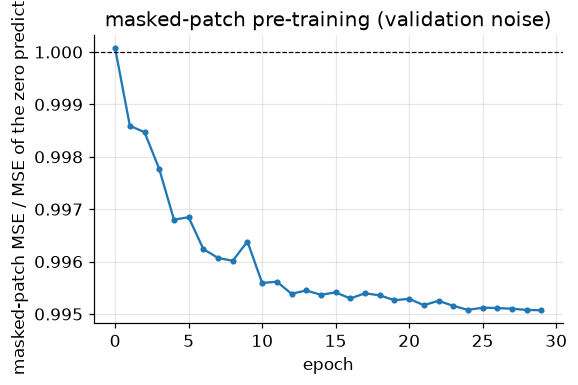

In [4]:
def fit_model(name, builder, X, y, Xv, yv, loss, epochs=EPOCHS, lr=1e-3, bs=128, seed=0):
    fn = os.path.join(MODELS, name + ".weights.h5"); hf = os.path.join(MODELS, name + "_hist.json")
    m, att = builder(seed)
    if os.path.exists(fn):
        m.load_weights(fn); return m, att, json.load(open(hf))
    steps = int(np.ceil(len(X) / bs))
    sched = keras.optimizers.schedules.CosineDecay(0.0, epochs * steps, alpha=0.02, warmup_target=lr, warmup_steps=2 * steps)
    m.compile(keras.optimizers.AdamW(sched, weight_decay=1e-4), loss)
    h = m.fit(X, y, validation_data=(Xv, yv), epochs=epochs, batch_size=bs, verbose=0, shuffle=True,
              callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_loss")])
    hist = {k: [float(x) for x in v] for k, v in h.history.items() if k in ("loss", "val_loss")}
    m.save_weights(fn); json.dump(hist, open(hf, "w")); return m, att, hist

def pretrain_mae(epochs=PRE_EPOCHS, ratio=0.4, bs=128, lr=1e-3, seed=0):
    hf = os.path.join(MODELS, "mae_hist.json")
    if os.path.exists(PRE_FN): return json.load(open(hf))
    tf.keras.utils.set_random_seed(seed); r = np.random.default_rng(seed)
    e = Enc(); inp = L.Input((g.NWIN, 1)); msk = L.Input((NP, 1))
    h, _ = e(inp, msk); mae = keras.Model([inp, msk], L.Dense(PATCH, name="mae_dec")(h)); encm = keras.Model(inp, e(inp)[0])
    X = clip(DS["train"]["noise"]); Xv = clip(DS["val"]["noise"])
    tgt, tgt_v = X.reshape(-1, NP, PATCH), Xv.reshape(-1, NP, PATCH); X, Xv = X[..., None], Xv[..., None]
    mv = (np.random.default_rng(1).random((len(Xv), NP, 1)) < ratio).astype(np.float32)
    steps = int(np.ceil(len(X) / bs))
    mae.compile(keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(0.0, epochs * steps, alpha=0.02, warmup_target=lr, warmup_steps=steps), weight_decay=1e-4), "mse")
    hist = dict(train=[], val=[], zero_val=float((tgt_v ** 2).mean(-1)[mv[..., 0] > 0].mean()))
    for ep in range(epochs):
        mk = (r.random((len(X), NP, 1)) < ratio).astype(np.float32)
        h_ = mae.fit([X, mk], tgt, sample_weight=mk[..., 0], batch_size=bs, epochs=1, verbose=0)
        hist["train"].append(float(h_.history["loss"][0]) / ratio)
        pv = mae.predict([Xv, mv], batch_size=1024, verbose=0)
        hist["val"].append(float(((pv - tgt_v) ** 2).mean(-1)[mv[..., 0] > 0].mean()))
    encm.save_weights(PRE_FN); json.dump(hist, open(hf, "w")); return hist

t0_ = time.time(); mae_hist = pretrain_mae()
print("pre-training done (%.0f s): validation MSE on masked patches %.4f, zero predictor %.4f, ratio %.3f" % (time.time() - t0_, mae_hist["val"][-1], mae_hist["zero_val"], mae_hist["val"][-1] / mae_hist["zero_val"]))
fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax.plot(np.array(mae_hist["val"]) / mae_hist["zero_val"], marker="o", ms=3)
ax.axhline(1, color="k", ls="--", lw=.8); ax.set_xlabel("epoch"); ax.set_ylabel("masked-patch MSE / MSE of the zero predictor"); ax.set_title("masked-patch pre-training (validation noise)")
g.savefig(fig, "fig06_pretraining"); plt.show()
summary["pretraining"] = dict(final_ratio=mae_hist["val"][-1] / mae_hist["zero_val"], epochs=len(mae_hist["val"]))

## 3. Training

For each architecture: binary detectors (noise vs any signal) and 4-class classifiers, `NSEED` = 2 independent seeds each so that ensembles can be formed. Transformers are trained from scratch (`tf`) and from the pre-trained encoder (`tfp`); the recurrent baseline (`gru`) is trained once. The 5-member binary CNN ensemble of notebook 05 is loaded as is.

tf_bin   trained / loaded (0 s cumulative); epochs [25, 12], best val loss [0.3121, 0.3102]
tfp_bin  trained / loaded (0 s cumulative); epochs [12, 12], best val loss [0.303, 0.3066]


gru_bin  trained / loaded (0 s cumulative); epochs [12], best val loss [0.2922]
tf_mc    trained / loaded (1 s cumulative); epochs [12, 12], best val loss [0.5059, 0.5252]


tfp_mc   trained / loaded (1 s cumulative); epochs [12, 12], best val loss [0.5059, 0.5025]
gru_mc   trained / loaded (1 s cumulative); epochs [12], best val loss [0.4561]
cnn_mc   trained / loaded (1 s cumulative); epochs [12, 12], best val loss [0.4239, 0.4047]


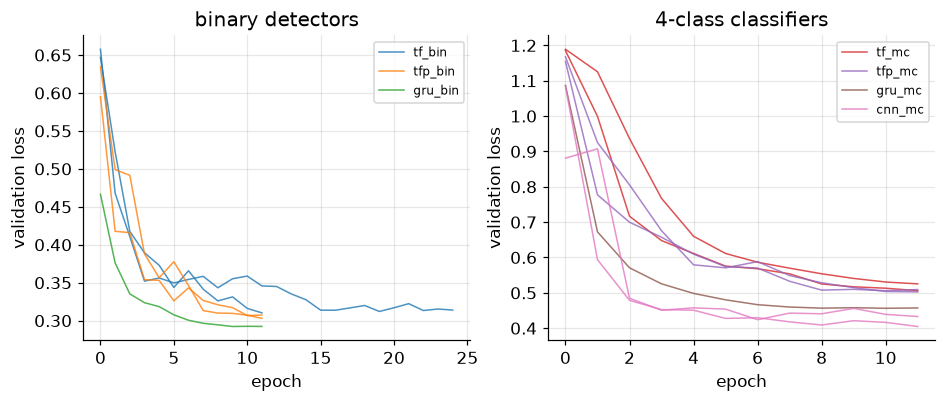

In [5]:
bce = keras.losses.BinaryCrossentropy(from_logits=True); sce = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
XT, XV = DS["train"]["X"], DS["val"]["X"]
SPEC = {   # group -> (mixer or 'cnn', nout, pretrained, n seeds)
    "tf_bin": ("attn", 1, False, NSEED), "tfp_bin": ("attn", 1, True, NSEED), "gru_bin": ("gru", 1, False, 1),
    "tf_mc": ("attn", 4, False, NSEED), "tfp_mc": ("attn", 4, True, NSEED), "gru_mc": ("gru", 4, False, 1), "cnn_mc": ("cnn", 4, False, NSEED)}
MD, HIST, ATT = {}, {}, {}
t0_ = time.time()
for grp, (mixer, nout, pre, ns) in SPEC.items():
    builder = (lambda s, nout=nout: build_cnn(nout, s)) if mixer == "cnn" else (lambda s, mixer=mixer, nout=nout, pre=pre: build_clf(mixer, nout, s, pre))
    y_, yv_, loss = (DS["train"]["yb"], DS["val"]["yb"], bce) if nout == 1 else (DS["train"]["y4"], DS["val"]["y4"], sce)
    MD[grp], HIST[grp], ATT[grp] = [], [], []
    for s in range(ns):
        m, att, h = fit_model(f"{grp}_s{s}", builder, XT, y_, XV, yv_, loss, seed=s)
        MD[grp].append(m); HIST[grp].append(h); ATT[grp].append(att)
    print("%-8s trained / loaded (%.0f s cumulative); epochs %s, best val loss %s" % (grp, time.time() - t0_, [len(h["loss"]) for h in HIST[grp]], [round(min(h["val_loss"]), 4) for h in HIST[grp]]))
MD["cnn_bin"] = [keras.models.load_model(os.path.join(MODELS, f"cnn_mix_s{s}.keras")) for s in range(5)]       # notebook 05
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, grps in zip(ax, (("tf_bin", "tfp_bin", "gru_bin"), ("tf_mc", "tfp_mc", "gru_mc", "cnn_mc"))):
    for grp in grps:
        for i, h in enumerate(HIST[grp]):
            l, = a.plot(h["val_loss"], color=f"C{list(SPEC).index(grp)}", lw=1, alpha=.8, label=grp if i == 0 else None)
    a.set_xlabel("epoch"); a.set_ylabel("validation loss"); a.legend(fontsize=8)
ax[0].set_title("binary detectors"); ax[1].set_title("4-class classifiers")
g.savefig(fig, "fig06_training"); plt.show()

## 4. Is pre-training worth anything? Label efficiency

The same three networks (CNN, Transformer from scratch, Transformer from the pre-trained encoder) trained on 250 / 1000 / 4000 labelled windows **per class** (noise and signal) and on the full set. The score is the AUC on the balanced test set of notebook 05 (noise + mixed injections SNR 3–15, test chunks), where the CNN ensemble reaches 0.994.

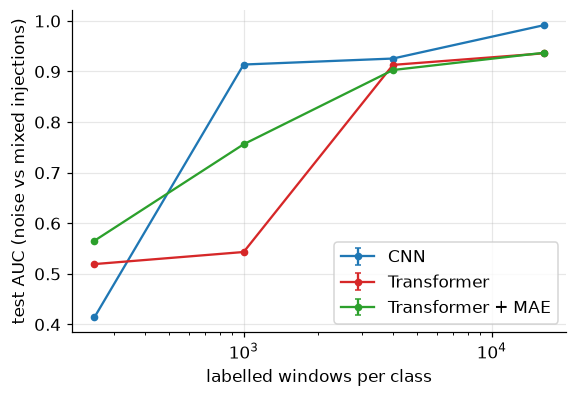

model,CNN,Transformer,Transformer + MAE
n_per_class,,,
250,0.4137,0.5193,0.5653
1000,0.9138,0.5432,0.7562
4000,0.9256,0.9131,0.9029
16224,0.9915,0.9359,0.9370


In [6]:
def eval_set(sp, seed):
    v, cid = data[sp]; r = np.random.default_rng(seed)
    sig, kinds, snr = make_signals(v, S1[sp], list(g.MORPHS), r)
    return np.concatenate([v, sig]), np.r_[np.zeros(len(v)), np.ones(len(v))], np.r_[np.full(len(v), np.nan), snr]
Ev = {sp: eval_set(sp, s) for sp, s in (("val", 11), ("test", 12))}
def logit(m, v, bs=1024):
    o = m.predict(clip(v)[..., None], verbose=0, batch_size=bs); return o[:, 0] if o.shape[1] == 1 else o
NLAB = [250, 1000, 4000]; rows = []
ntr = len(DS["train"]["noise"])
for n in NLAB:
    r = np.random.default_rng(n); ii = r.choice(ntr, n, replace=False)
    sel = np.r_[ii, ntr + r.choice(ntr, n, replace=False)]
    for lab, builder in (("CNN", lambda s: build_cnn(1, s)), ("Transformer", lambda s: build_clf("attn", 1, s, False)), ("Transformer + MAE", lambda s: build_clf("attn", 1, s, True))):
        aucs = []
        for s in range(1):
            m, _, _ = fit_model(f"lab_{lab.replace(' + ', '')}_{n}_s{s}", builder, XT[sel], DS["train"]["yb"][sel], XV, DS["val"]["yb"], bce, seed=s)
            aucs.append(roc_auc_score(Ev["test"][1], logit(m, Ev["test"][0])))
        rows.append(dict(n_per_class=n, model=lab, AUC=float(np.mean(aucs)), AUC_spread=float(np.std(aucs))))
for lab, grp in (("CNN", "cnn_bin"), ("Transformer", "tf_bin"), ("Transformer + MAE", "tfp_bin")):
    a_ = [roc_auc_score(Ev["test"][1], logit(m, Ev["test"][0])) for m in MD[grp][:2]]
    rows.append(dict(n_per_class=ntr, model=lab, AUC=float(np.mean(a_)), AUC_spread=float(np.std(a_))))
lab_tab = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(5.8, 3.8))
for lab, c in (("CNN", g.COLORS["freq"]), ("Transformer", g.COLORS["bayes"]), ("Transformer + MAE", g.COLORS["ml"])):
    d = lab_tab[lab_tab.model == lab]; ax.errorbar(d.n_per_class, d.AUC, d.AUC_spread, marker="o", ms=4, color=c, label=lab, capsize=2)
ax.set_xscale("log"); ax.set_xlabel("labelled windows per class"); ax.set_ylabel("test AUC (noise vs mixed injections)"); ax.legend()
g.savefig(fig, "fig06_label_efficiency"); plt.show()
summary["label_efficiency"] = rows
lab_tab.pivot(index="n_per_class", columns="model", values="AUC").round(4)

How to read the label-efficiency table (test AUC, one seed per point, so differences of a few 10⁻² at small $n$ are within the seed-to-seed scatter shown by the error bars):

* **The pre-training task learned almost nothing about the noise**: the masked-patch error is 0.995 of the error of the zero predictor. White noise offers nothing to predict from the neighbours, the same reason why the autoencoder of notebook 05 does not beat excess power.
* The pre-trained encoder is nevertheless a better *starting point* with 1000 labelled windows per class (AUC 0.76 against 0.54 for the same network from random weights), and equal within the scatter at 4000 and with the full set (0.90–0.94). I do not claim to know why (an initialisation/optimisation effect is more likely than knowledge of the noise); the plain CNN is already at 0.91 with 1000 windows per class and is the best model at every size but the smallest, where nothing has converged (AUC ≈ 0.4–0.5).
* With the full training set the CNN (the first two members of the notebook-05 ensemble) reaches 0.9915, the Transformers 0.936–0.937.

## 5. Hypothesis banks: frequentist and Bayesian model comparison

For each morphology family $\mathcal M_f$ a bank of whitened templates (unit norm, one per parameter point) is correlated with the data at every time shift $\tau\in[0.15,0.85]$ s with the FFT trick of notebook 03:

* sine-Gaussian: 40 central frequencies (log-spaced 40–450 Hz) × 4 quality factors (3, 6, 10, 16): 160 templates, phase-free (χ² with 2 d.o.f.);
* Gaussian pulse: 14 widths (log-spaced 0.8–5 ms): the template is real, so the statistic is $(\mathrm{Re}\,z)^2$ (1 d.o.f.);
* chirp: 6 $f_0$ (50–150 Hz) × 5 $\dot f$ (150–600 Hz/s) × 4 $\sigma_t$ (30–80 ms) = 120 templates, phase-free.

**Frequentist model comparison.** $\rho^2_{f}=\max_{\theta,\tau}\rho^2(\theta,\tau;\mathcal M_f)$ is twice the profile log-likelihood ratio of family $f$ against noise. Choosing the family with the largest $\rho^2_f$ ignores that the families have different numbers of templates and degrees of freedom (a trial factor that favours the largest bank); the second frequentist rule therefore replaces $\rho^2_f$ by $-\ln p_f$, where $p_f$ is the empirical background probability of $\rho^2_f$ on the validation noise (ties of the loudest signals are broken by $\rho^2$).

**Bayesian model comparison.** With the amplitude marginalised analytically ($\sigma_\rho = 10$, as in notebook 04) and a uniform prior on the template grid and on $\tau$, the Bayes factor against noise is $B_f=\langle \exp\ln L(\theta,\tau;\mathcal M_f)\rangle_{\theta,\tau}$. The prior-averaging (Occam factor) is what penalises the bigger families. Posteriors use the prior of the training set (noise ½, each morphology ⅙), so that supervised networks and the Bayesian classifier are evaluated on the same problem.

For the 4-class decision all methods use the **same rule**: a window is called *noise* if its own detection statistic is below the 99 % quantile of the validation noise (FAP = 10⁻²), otherwise the morphology with the largest score is assigned.

In [7]:
class FamilyBank:
    def __init__(self, kind, S1_, band=g.BAND):
        f = g.FREQ[None, :]; self.dof = 2
        if kind == "sg":
            f0, Q = np.meshgrid(np.geomspace(40, 450, 40), [3., 6., 10., 16.])
            T = g.sine_gaussian_ft(f, f0.ravel()[:, None], Q.ravel()[:, None], 0.0, positive_only=True)
        elif kind == "pulse":
            T = g.gaussian_pulse_ft(f, np.geomspace(0.8e-3, 5e-3, 14)[:, None]); self.dof = 1
        else:
            f0, fd, sg = np.meshgrid(np.linspace(50, 150, 6), np.linspace(150, 600, 5), np.linspace(.03, .08, 4))
            T = g._cgauss(f, f0.ravel()[:, None], fd.ravel()[:, None], sg.ravel()[:, None])
        T = T / np.sqrt(S1_)[None, :] * band
        self.T = (T / np.sqrt((np.abs(T) ** 2).sum(1, keepdims=True))).astype(np.complex64)

    def scan(self, X, sigma=10.0, tau=(0.15, 0.85), batch=48):
        i0, i1 = int(tau[0] * g.NWIN), int(tau[1] * g.NWIN); s2 = sigma ** 2
        rho2 = np.zeros(len(X), np.float32); lnbf = np.zeros(len(X), np.float32)
        for a in range(0, len(X), batch):
            xb = X[a:a + batch].astype(np.complex64)
            Z = np.zeros((len(xb), len(self.T), g.NWIN), np.complex64); Z[..., :g.NB] = xb[:, None, :] * np.conj(self.T)[None]
            z = sfft.ifft(Z, axis=-1, workers=-1)[..., i0:i1] * g.NWIN
            r2 = (np.abs(z) ** 2 if self.dof == 2 else z.real ** 2).reshape(len(xb), -1)
            rho2[a:a + batch] = r2.max(1)
            lnl = 0.5 * r2 * s2 / (1 + s2) - 0.5 * self.dof * np.log1p(s2)
            mx = lnl.max(1); lnbf[a:a + batch] = mx + np.log(np.exp(lnl - mx[:, None]).mean(1))
        return rho2, lnbf

BANKS = {i: {k: FamilyBank(k, CH[i]["S1"]) for k in g.MORPHS} for i in CH}
def scan_families(series, cid):
    r2 = np.zeros((len(series), 3), np.float32); lb = np.zeros((len(series), 3), np.float32)
    for c in np.unique(cid):
        m = cid == c; X = g.to_bins(series[m])
        for j, k in enumerate(g.MORPHS): r2[m, j], lb[m, j] = BANKS[c][k].scan(X)
    return r2, lb
# sanity: on pure noise rho2 is a chi-square-like maximum over many correlated trials, and ln B is ~0 on average
t0_ = time.time(); r2_, lb_ = scan_families(data["val"][0][:200], data["val"][1][:200])
print("scan of 200 noise windows: %.1f s;  median max-rho2 (sg, pulse, chirp) = %s; mean lnB = %s" % (time.time() - t0_, np.median(r2_, 0).round(1), lb_.mean(0).round(2)))

scan of 200 noise windows: 0.4 s;  median max-rho2 (sg, pulse, chirp) = [17.6 12.  15.9]; mean lnB = [-2.4  -1.25 -2.57]


## 6. Test sets and all the statistics

Same test injections as notebook 05 (seed 777; each morphology × SNR ∈ {3, …, 16} × 500 windows drawn from the **test** chunks) and the same background chunks: **validation** noise for the thresholds, **test** noise for the observed false-alarm probability. Every raw output (family statistics and the logits of every network) is cached in `cache/stats06.pkl`.

In [8]:
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 500
vte, cte = data["test"]; S1te = S1["test"]; r = np.random.default_rng(777); TEST = {}
for kind in g.MORPHS:
    for snr in SNRS:
        idx = r.choice(len(vte), NINJ, replace=False)
        TEST[(kind, snr)] = (g.inject(vte[idx], kind, float(snr), r, S1te[idx])[0], cte[idx])

NET_GROUPS = ["cnn_bin", "tf_bin", "tfp_bin", "gru_bin", "cnn_mc", "tf_mc", "tfp_mc", "gru_mc"]
def raw_all(v, cid):
    out = {}; out["rho2"], out["lnbf"] = scan_families(v, cid)
    for grp in NET_GROUPS:
        ls = [logit(m, v) for m in MD[grp]]
        out[grp] = np.mean(ls, 0); out[grp + "_s0"] = ls[0]
    return out
STATS_FN = os.path.join(g.CACHE, "stats06.pkl")
if os.path.exists(STATS_FN):
    RAW = pickle.load(open(STATS_FN, "rb"))
else:
    t0_ = time.time(); RAW = {"val": raw_all(*data["val"]), "test": raw_all(*data["test"])}
    print("background: %.0f s" % (time.time() - t0_))
    for k, (v, c) in TEST.items(): RAW[k] = raw_all(v, c)
    print("injections: %.0f s" % (time.time() - t0_)); pickle.dump(RAW, open(STATS_FN, "wb"))
print(len(RAW), "sets;", {k: v.shape for k, v in RAW["val"].items() if k in ("rho2", "tf_mc", "tf_bin")})

35 sets; {'rho2': (8112, 3), 'tf_bin': (8112,), 'tf_mc': (8112, 4)}


In [9]:
BKG_R2 = np.sort(RAW["val"]["rho2"], axis=0)
def pvalue_score(r2):
    cnt = np.stack([len(BKG_R2) - np.searchsorted(BKG_R2[:, j], r2[:, j], side="left") for j in range(3)], 1)    # background windows with rho2 >= x
    return -np.log((cnt + 1.0) / (len(BKG_R2) + 1.0)) + 1e-6 * r2

PRETTY = {"cnn_bin": "CNN", "tf_bin": "Transformer", "tfp_bin": "Transformer + MAE", "gru_bin": "GRU", "cnn_mc": "CNN 4-class", "tf_mc": "Transformer 4-class", "tfp_mc": "Transformer + MAE 4-class", "gru_mc": "GRU 4-class"}
def statistics(raw):
    """name -> (detection statistic (n,), morphology scores (n,3) or None)."""
    r2, lb = raw["rho2"], raw["lnbf"]; ps = pvalue_score(r2); out = {}
    out["matched-filter bank (SG)"] = (r2[:, 0], None)
    out["Freq. (max ρ²)"] = (r2.max(1), r2); out["Freq. (p-value)"] = (ps.max(1), ps)
    out["Bayes (3 families)"] = (logsumexp(lb, axis=1) - np.log(3), lb)
    for grp in NET_GROUPS:
        for suffix, tag in (("", ""), ("_s0", " (single)")):
            z = raw[grp + suffix]
            if grp.endswith("_bin"): out[PRETTY[grp] + tag] = (z, None)
            else: out[PRETTY[grp] + tag] = (logsumexp(z[:, 1:], axis=1) - z[:, 0], z[:, 1:])
    return out
ST = {k: statistics(v) for k, v in RAW.items()}
NAMES = list(ST["val"].keys())
FAP = 1e-2
thr = lambda name, far: g.threshold_at_far(ST["val"][name][0], far)
print(len(NAMES), "statistics")

20 statistics


## 7. Detection: efficiency at fixed false-alarm probability

Thresholds are the (1 − FAP) quantiles of each statistic on the validation noise windows; efficiency and ρ₅₀ / ρ₉₀ (SNR at 50 % / 90 % efficiency, linear interpolation) are measured on the test injections. The observed test false-alarm probability checks the transfer of the threshold to chunks that were not used for it.

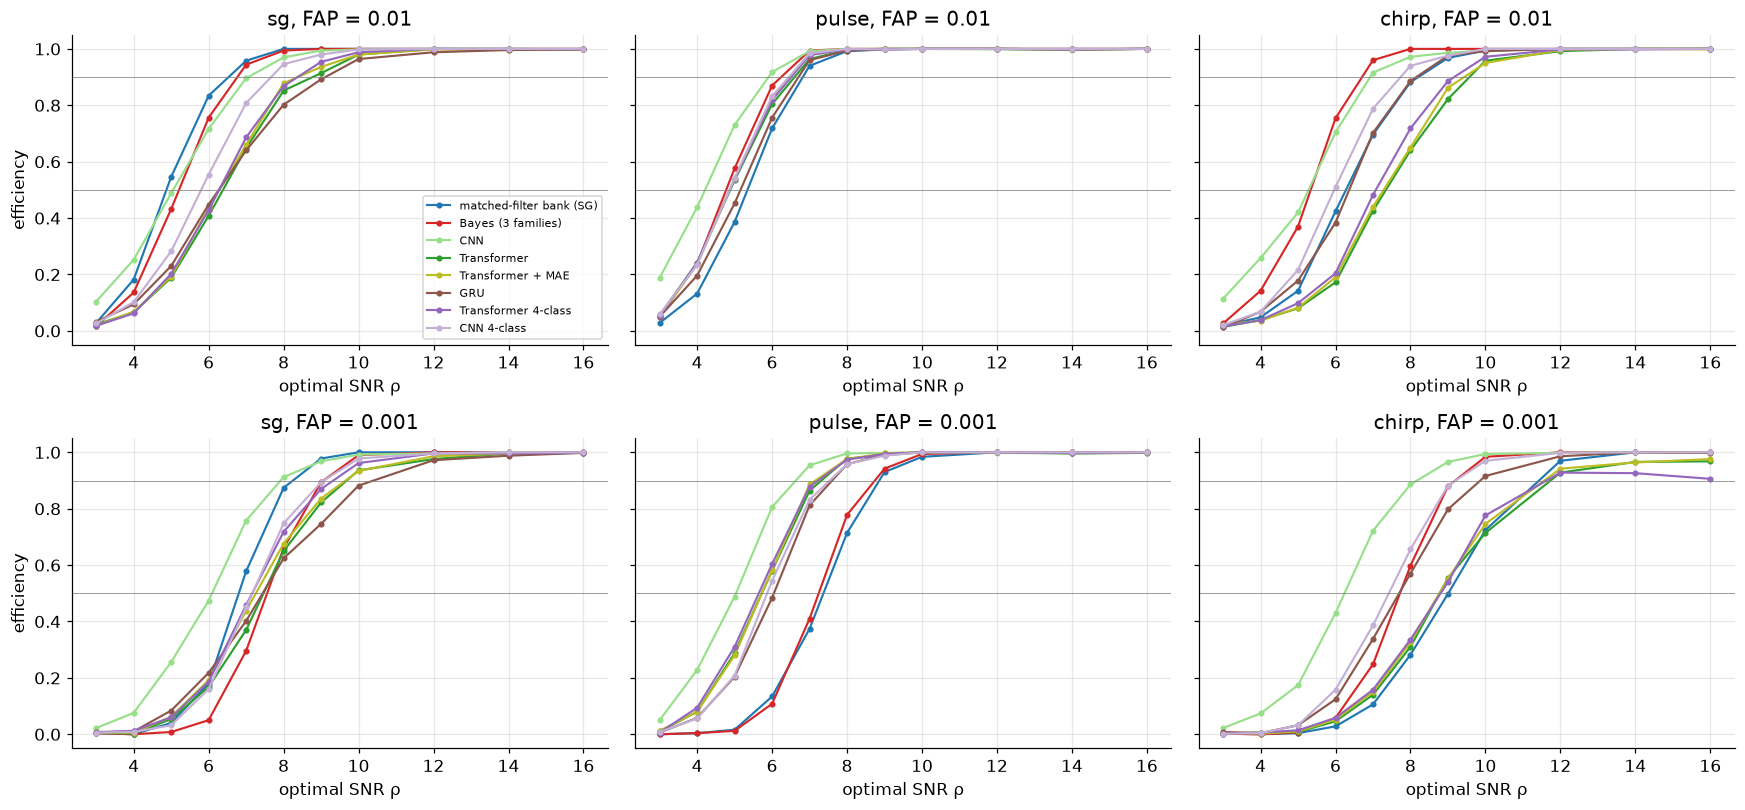

rho50 | rho90 (thresholds from validation noise)


,sg ρ50,pulse ρ50,chirp ρ50,sg ρ90,pulse ρ90,chirp ρ90,observed_test_FAP
FAP = 0.01,,,,,,,
Bayes (3 families),5.21,4.78,5.34,6.77,6.24,6.71,0.0071
CNN,5.05,4.21,5.28,7.05,5.90,6.92,0.0053
CNN (single),5.56,4.62,5.71,7.80,6.52,7.64,0.0035
CNN 4-class,5.80,4.86,5.97,7.67,6.45,7.74,0.0073
GRU,6.27,5.16,6.36,9.11,6.71,8.16,0.0097
Transformer,6.38,4.88,7.35,8.77,6.60,9.57,0.0083
Transformer (single),6.49,5.09,7.44,8.88,6.75,9.67,0.0088
Transformer + MAE,6.29,4.87,7.29,8.38,6.48,9.43,0.0092
Transformer + MAE (single),6.38,4.96,7.28,8.68,6.57,9.62,0.0088


,sg ρ50,pulse ρ50,chirp ρ50,sg ρ90,pulse ρ90,chirp ρ90,observed_test_FAP
FAP = 0.001,,,,,,,
Bayes (3 families),7.56,7.24,7.72,9.06,8.74,9.19,0.0016
CNN,6.09,5.04,6.24,7.92,6.64,8.18,0.0010
CNN (single),6.51,5.39,6.71,8.75,7.00,8.77,0.0006
CNN 4-class,7.17,5.87,7.42,9.07,7.54,9.20,0.0017
GRU,7.44,6.05,7.70,10.40,7.60,9.86,0.0020
Transformer,7.46,5.73,8.78,9.68,7.32,11.74,0.0018
Transformer (single),7.72,5.95,8.92,9.90,7.67,11.84,0.0023
Transformer + MAE,7.26,5.73,8.77,9.65,7.16,11.57,0.0020
Transformer + MAE (single),7.30,5.66,8.64,9.84,7.05,11.45,0.0023


In [10]:
def eff_curve(kind, name, far):
    t = thr(name, far); return np.array([g.efficiency(ST[(kind, s)][name][0], t)[0] for s in SNRS])
def levels(e):
    x = np.array(SNRS, float); f = lambda lv: float(np.interp(lv, np.maximum.accumulate(e), x)) if e.max() >= lv else np.nan
    return f(.5), f(.9)
rows = []
for far in (1e-2, 1e-3):
    for name in NAMES:
        t = thr(name, far); obs = float((ST["test"][name][0] > t).mean())
        for kind in g.MORPHS:
            e = eff_curve(kind, name, far); r50, r90 = levels(e)
            rows.append(dict(FAP=far, statistic=name, morphology=kind, rho50=r50, rho90=r90, eff_rho8=float(e[SNRS.index(8)]), observed_test_FAP=obs))
det_tab = pd.DataFrame(rows)
SHOW = ["matched-filter bank (SG)", "Bayes (3 families)", "CNN", "Transformer", "Transformer + MAE", "GRU", "Transformer 4-class", "CNN 4-class"]
col = {"matched-filter bank (SG)": g.COLORS["freq"], "Bayes (3 families)": g.COLORS["bayes"], "CNN": "#98df8a", "Transformer": g.COLORS["ml"], "Transformer + MAE": "#bcbd22", "GRU": "#8c564b",
       "Transformer 4-class": g.COLORS["purple"], "CNN 4-class": "#c5b0d5"}
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5), sharey=True)
for row, far in zip(ax, (1e-2, 1e-3)):
    for a, kind in zip(row, g.MORPHS):
        for name in SHOW: a.plot(SNRS, eff_curve(kind, name, far), color=col[name], marker="o", ms=3, lw=1.4, label=name)
        a.set_title(f"{kind}, FAP = {far:g}"); a.set_xlabel("optimal SNR ρ"); a.axhline(.9, color="grey", lw=.5); a.axhline(.5, color="grey", lw=.5)
    row[0].set_ylabel("efficiency")
ax[0, 0].legend(fontsize=7.5, loc="lower right"); fig.tight_layout()
g.savefig(fig, "fig06_efficiency"); plt.show()
t = det_tab[det_tab.statistic.isin(SHOW + ["CNN (single)", "Transformer (single)", "Transformer + MAE (single)"])]
print("rho50 | rho90 (thresholds from validation noise)")
for far in (1e-2, 1e-3):
    p = lambda c: t[t.FAP == far].pivot(index="statistic", columns="morphology", values=c)[list(g.MORPHS)].round(2)
    display(p("rho50").join(p("rho90"), lsuffix=" ρ50", rsuffix=" ρ90").join(t[t.FAP == far].groupby("statistic").observed_test_FAP.first().round(4)).rename_axis(f"FAP = {far:g}"))

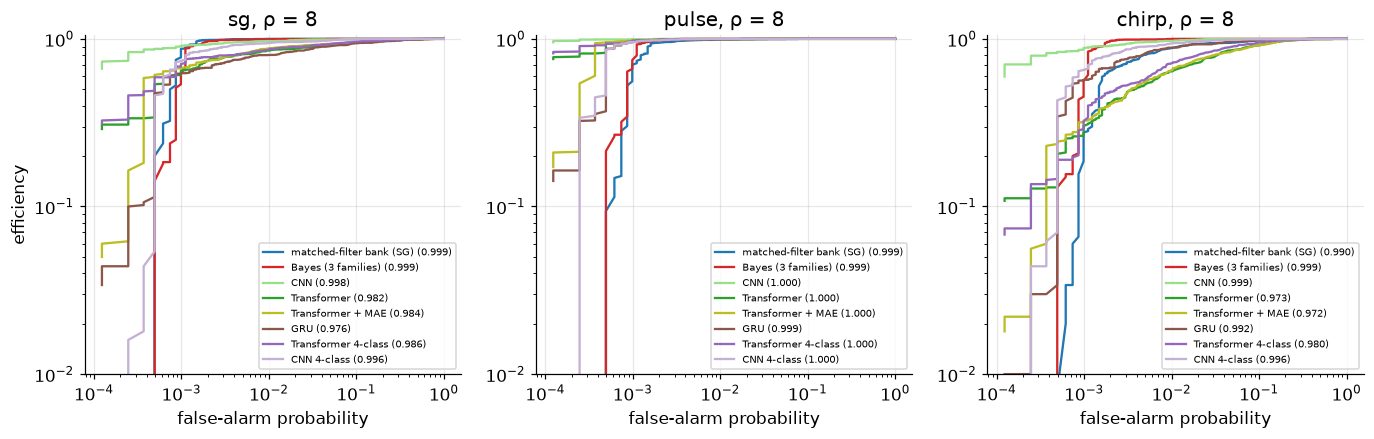

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, kind in zip(ax, g.MORPHS):
    for name in SHOW:
        b = ST["val"][name][0]; s_ = ST[(kind, 8)][name][0]
        far, e = g.roc(b, s_); a.loglog(far, np.maximum(e, 1e-3), color=col[name], label=f"{name} ({g.auc(b, s_):.3f})")
    a.set_title(f"{kind}, ρ = 8"); a.set_xlabel("false-alarm probability"); a.set_ylim(1e-2, 1.05); a.legend(fontsize=6.5, loc="lower right")
ax[0].set_ylabel("efficiency")
g.savefig(fig, "fig06_roc"); plt.show()
summary["detection"] = det_tab.to_dict("records")

How to read the efficiency curves and tables (thresholds from the same validation noise for every statistic; all Transformers and GRUs trained for at most 12 epochs because of the CPU budget — the first seed of the from-scratch Transformer was trained for 25 epochs and ends with the same validation loss, 0.312, as the 12-epoch one, 0.310, so more epochs alone do not close the gap; depth, width and patch size were **not** tuned):

* **FAP = 10⁻².** The best methods are the 5-member CNN ensemble and the Bayes factor of the three families (ρ₅₀ = 5.05 / 4.21 / 5.28 and 5.21 / 4.78 / 5.34 for sine-Gaussian / pulse / chirp), followed by the matched-filter bank of sine-Gaussians (4.87 / 5.34 / 6.28: the best on its own family, worse on the others). The GRU (6.27 / 5.16 / 6.36) and the Transformer (ensemble 6.38 / 4.88 / 7.35) are about one to two SNR units behind the CNN on sine-Gaussians and chirps and equal to it only on the pulses; at ρ₉₀ on chirps the Transformer needs 9.6 against 6.9 for the CNN ensemble.
* **FAP = 10⁻³.** The ranking is the same and the gap grows: ρ₅₀ of the CNN ensemble 6.09 / 5.04 / 6.24, of the Transformer 7.46 / 5.73 / 8.78, of the bank 6.80 / 7.37 / 9.01, of the Bayes factor 7.56 / 7.24 / 7.72. The efficiency of the Transformer on chirps even saturates below 1 at ρ = 16 for the 4-class version (0.91), i.e. a few loud chirps stay below the threshold set by the validation glitches.
* **Parameters are not the explanation.** The Transformer has 114 000 parameters, the GRU 88 000, the CNN 17 800. The CNN's local filters followed by a global max-pool encode the two things the task needs — a burst is localised, and it can be anywhere in the window — and this prior is worth more than the flexibility of attention at this training-set size (~16 000 windows per class), which is the regime where the label-efficiency figure also shows the Transformers lagging.
* **Pre-training.** The pre-trained encoder changes nothing at the level of ρ₅₀ (6.29 / 4.87 / 7.29 against 6.38 / 4.88 / 7.35).
* **Observed false-alarm probability on the test chunks** at a nominal 10⁻²: 0.5 % (CNN ensemble), 0.7–0.9 % (Bayes, Transformer, bank), 1.0 % (GRU); at a nominal 10⁻³: 0.10 % (CNN ensemble), 0.15–0.23 % for the others, so the thresholds of the Transformers and the GRU transfer slightly worse to the test epochs.

### Glitch rejection

The noise windows are real, so some contain loud transients. Taking the 5 % of the **test** noise windows with the largest $\max|v|$ as the "glitchy" subset, the table gives, at the threshold that corresponds to a global FAP of 10⁻² on the validation noise, (i) the alarm rate inside the glitchy subset (a detector that does not mistake glitches for bursts has a low rate there) and the fraction of all test false alarms that come from it, and (ii) the efficiency for a ρ = 8 injection placed **inside** the glitchy windows (does a glitch hide a signal?).

In [12]:
mx = np.abs(vte).max(1); gl = np.where(mx >= np.quantile(mx, .95))[0]
print("glitchy subset: %d windows, max|v| >= %.1f sigma (median window: %.1f sigma)" % (len(gl), mx[gl].min(), np.median(mx)))
rg = np.random.default_rng(99); GL = {}
for kind in g.MORPHS:
    ser, _, _ = g.inject(vte[gl], kind, 8.0, rg, S1te[gl]); GL[kind] = statistics(raw_all(ser, cte[gl]))
rows = []
for name in SHOW + ["CNN (single)", "Transformer (single)"]:
    t = thr(name, FAP); a_ = ST["test"][name][0] > t
    rows.append(dict(statistic=name, alarm_rate_glitchy=float(a_[gl].mean()), alarm_rate_rest=float(np.delete(a_, gl).mean()), share_of_false_alarms_from_glitchy=float(a_[gl].sum() / max(a_.sum(), 1)),
                     eff_rho8_in_glitchy=float(np.mean([(GL[k][name][0] > t).mean() for k in g.MORPHS])), eff_rho8_all=float(np.mean([(ST[(k, 8)][name][0] > t).mean() for k in g.MORPHS]))))
gl_tab = pd.DataFrame(rows).set_index("statistic"); summary["glitches"] = rows
gl_tab.round(3)

glitchy subset: 406 windows, max|v| >= 3.9 sigma (median window: 3.2 sigma)


,alarm_rate_glitchy,alarm_rate_rest,share_of_false_alarms_from_glitchy,eff_rho8_in_glitchy,eff_rho8_all
statistic,,,,,
matched-filter bank (SG),0.069,0.005,0.406,0.955,0.958
Bayes (3 families),0.057,0.005,0.397,0.995,0.998
CNN,0.027,0.004,0.256,0.963,0.981
Transformer,0.049,0.006,0.299,0.828,0.829
Transformer + MAE,0.047,0.007,0.253,0.844,0.842
GRU,0.052,0.008,0.266,0.895,0.894
Transformer 4-class,0.042,0.006,0.258,0.851,0.861
CNN 4-class,0.052,0.005,0.356,0.961,0.962
CNN (single),0.020,0.003,0.286,0.927,0.957


The "glitchy" subset is the 5 % of test windows with the largest $\max|v|$ (≥ 3.9σ; the median window has 3.2σ), so it contains mild transients, not only loud glitches. All statistics over-represent it among their false alarms (it is 5 % of the windows):

* The matched-filter bank and the Bayes factor draw 40 % of their false alarms from it, the networks 25–30 %: the alarm rate inside the subset is 6.9 % (bank), 5.7 % (Bayes), 2.7 % (CNN ensemble), 4.9 % (Transformer), 5.2 % (GRU).
* The Transformer is **not** better than the CNN at rejecting glitches: the CNN ensemble has the lowest glitch alarm rate and the highest efficiency; the Transformers' efficiency at ρ = 8 is 0.83–0.86, against 0.96–0.98 (CNN) and 0.998 (Bayes factor).
* A glitch does not hide a ρ = 8 signal for any method: the efficiency in the glitchy windows is the same as in the others (e.g. 0.83 and 0.83 for the Transformer, 0.96 and 0.98 for the CNN ensemble).

### What does the attention look at?

Mean attention received by each patch in the last block of the (first) from-scratch Transformer, averaged over the heads and the query patches, for ρ = 10 injections. The localisation score is the fraction of windows in which the most attended patch is within ±1 patch (±16 ms) of the injection time $t_0$.

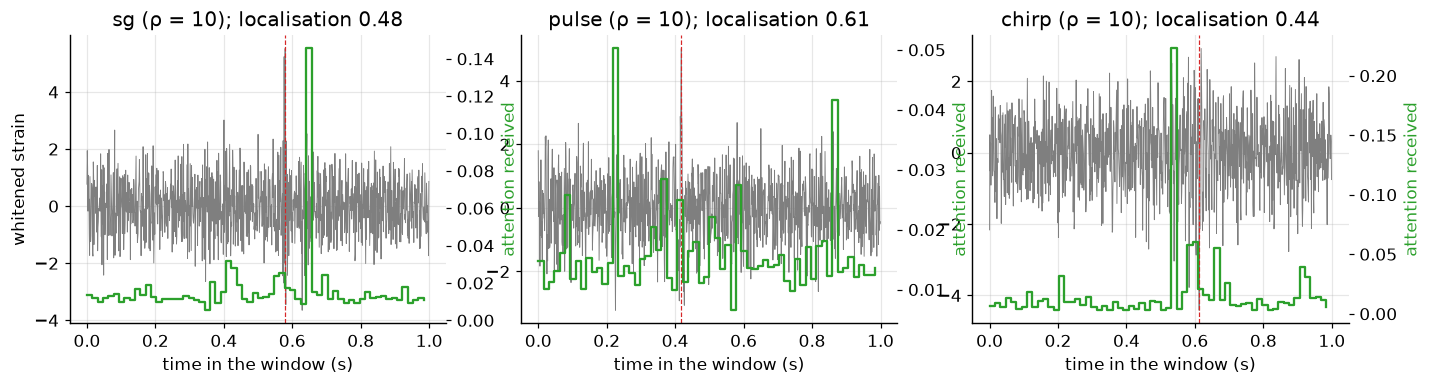

fraction of windows whose most attended patch is within ±1 of the injection: {'sg': 0.477, 'pulse': 0.61, 'chirp': 0.44}  (chance: 0.047)


In [13]:
att = ATT["tf_bin"][0]; ra = np.random.default_rng(5); loc = {}; ex = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for a, kind in zip(ax, g.MORPHS):
    idx = ra.choice(len(vte), 300, replace=False); ser, p, _ = g.inject(vte[idx], kind, 10.0, ra, S1te[idx])
    A = att.predict(clip(ser)[..., None], verbose=0, batch_size=300).mean((1, 2))          # (n, NP) attention received
    loc[kind] = float((np.abs(A.argmax(1) - np.floor(p["t0"] * NP)) <= 1).mean()); ex[kind] = (ser[0], A[0], p["t0"][0])
    t = np.arange(g.NWIN) / g.FS; a.plot(t, ser[0], color=g.COLORS["grey"], lw=.6); a.axvline(p["t0"][0], color=g.COLORS["bayes"], ls="--", lw=.8)
    b = a.twinx(); b.step(np.arange(NP) * PATCH / g.FS, A[0], where="post", color=g.COLORS["ml"]); b.set_ylabel("attention received", color=g.COLORS["ml"]); b.grid(False)
    a.set_title(f"{kind} (ρ = 10); localisation {loc[kind]:.2f}"); a.set_xlabel("time in the window (s)")
ax[0].set_ylabel("whitened strain"); g.savefig(fig, "fig06_attention"); plt.show()
print("fraction of windows whose most attended patch is within ±1 of the injection:", {k: round(v, 3) for k, v in loc.items()}, " (chance: %.3f)" % (3 / NP))
summary["attention_localisation"] = loc

The attention is informative: the most attended patch is within ±1 patch of the true burst time in 48 % (sine-Gaussian), 61 % (pulse) and 44 % (chirp) of the windows, against 4.7 % expected by chance. The chirps, which last 0.1–0.2 s, are the least localised, and they are also where the Transformer is weakest.

## 8. Signal hypothesis testing

Questions: given a signal that is above the detection threshold, which method tells which morphology generated it, and how does the answer degrade as the SNR decreases? Every method has a detection statistic $s$ and morphology scores $m_f$ (§6): networks — logit of "any signal" against noise and the three signal logits; frequentist — $\max_f\rho^2_f$ or $\max_f(-\ln p_f)$; Bayes — $\ln\frac13\sum_f B_f$ and $\ln B_f$. The common *gate* for the conditional analyses is the Bayesian detection statistic at FAP = 10⁻² (validation noise).

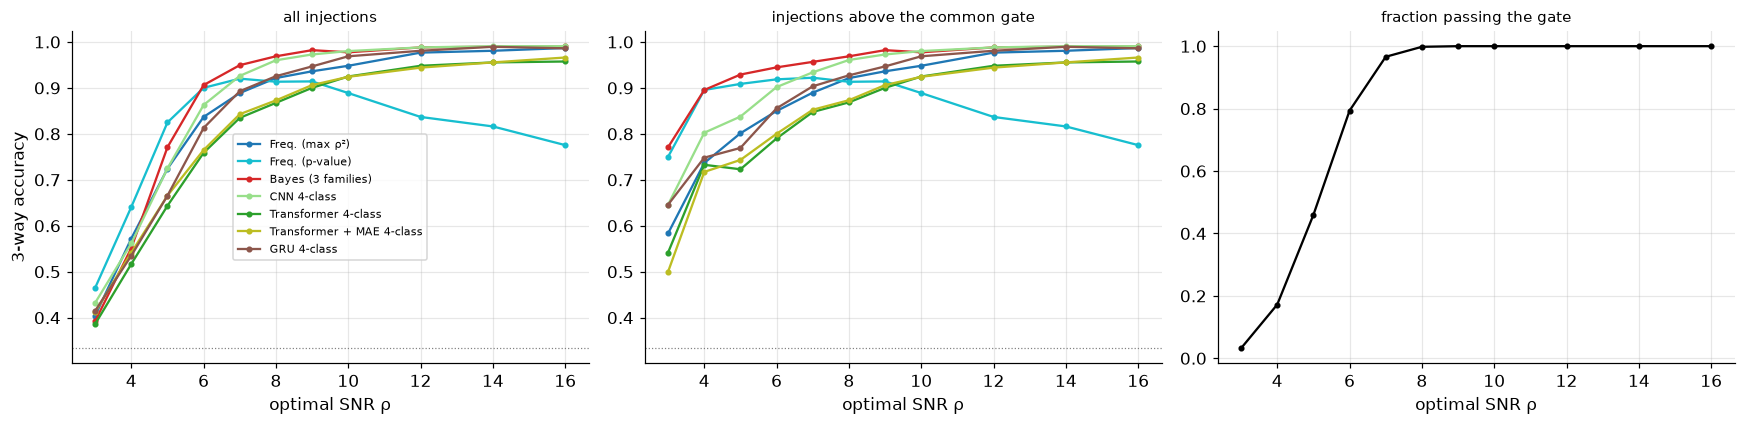

,ρ=5,ρ=6,ρ=8,ρ=10,ρ=14
Freq. (max ρ²),0.724,0.837,0.921,0.948,0.981
Freq. (p-value),0.825,0.900,0.913,0.889,0.816
Bayes (3 families),0.771,0.906,0.969,0.977,0.989
CNN 4-class,0.725,0.863,0.960,0.980,0.991
Transformer 4-class,0.643,0.759,0.867,0.925,0.955
Transformer + MAE 4-class,0.665,0.765,0.873,0.924,0.955
GRU 4-class,0.665,0.813,0.925,0.969,0.989


In [14]:
MC = ["Freq. (max ρ²)", "Freq. (p-value)", "Bayes (3 families)", "CNN 4-class", "Transformer 4-class", "Transformer + MAE 4-class", "GRU 4-class"]
mcol = {"Freq. (max ρ²)": g.COLORS["freq"], "Freq. (p-value)": "#17becf", "Bayes (3 families)": g.COLORS["bayes"], "CNN 4-class": "#98df8a", "Transformer 4-class": g.COLORS["ml"], "Transformer + MAE 4-class": "#bcbd22", "GRU 4-class": "#8c564b"}
def decide4(name, st):
    """4-class decision: noise below the FAP = 1e-2 threshold of the method's own statistic, else the highest morphology score."""
    s, m = st[name]; return np.where(s > thr(name, FAP), 1 + m.argmax(1), 0)
TRUE = {k: i + 1 for i, k in enumerate(g.MORPHS)}
gate = lambda st: st["Bayes (3 families)"][0] > thr("Bayes (3 families)", FAP)

# 3-way accuracy among signals vs SNR: all injections and injections that pass the common gate
acc_all = {n: {k: [] for k in g.MORPHS} for n in MC}; acc_gate = {n: [] for n in MC}; frac_gate = []
for snr in SNRS:
    ok = {n: [] for n in MC}; kept = []
    for k in g.MORPHS:
        st = ST[(k, snr)]; gt = gate(st); kept.append(gt)
        for n in MC:
            hit = st[n][1].argmax(1) == TRUE[k] - 1; acc_all[n][k].append(hit.mean()); ok[n].append(hit[gt])
    for n in MC: acc_gate[n].append(np.concatenate(ok[n]).mean() if np.concatenate(kept).any() else np.nan)
    frac_gate.append(np.concatenate(kept).mean())
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for n in MC:
    ax[0].plot(SNRS, np.mean([acc_all[n][k] for k in g.MORPHS], 0), color=mcol[n], marker="o", ms=3, label=n)
    ax[1].plot(SNRS, acc_gate[n], color=mcol[n], marker="o", ms=3)
ax[0].set_title("all injections", fontsize=10); ax[1].set_title("injections above the common gate", fontsize=10)
ax[2].plot(SNRS, frac_gate, "k-o", ms=3); ax[2].set_title("fraction passing the gate", fontsize=10)
for a in ax: a.set_xlabel("optimal SNR ρ")
ax[0].set_ylabel("3-way accuracy"); ax[0].axhline(1 / 3, color="grey", ls=":", lw=.8); ax[1].axhline(1 / 3, color="grey", ls=":", lw=.8); ax[0].legend(fontsize=7.5)
fig.tight_layout(); g.savefig(fig, "fig06_morphology_accuracy"); plt.show()
acc_tab = pd.DataFrame({n: [np.mean([acc_all[n][k][SNRS.index(s)] for k in g.MORPHS]) for s in (5, 6, 8, 10, 14)] for n in MC}, index=["ρ=5", "ρ=6", "ρ=8", "ρ=10", "ρ=14"]).T
summary["morphology_accuracy"] = dict(snr=SNRS, all={n: np.mean([acc_all[n][k] for k in g.MORPHS], 0).tolist() for n in MC}, gated={n: acc_gate[n] for n in MC}, gate_fraction=frac_gate)
acc_tab.round(3)

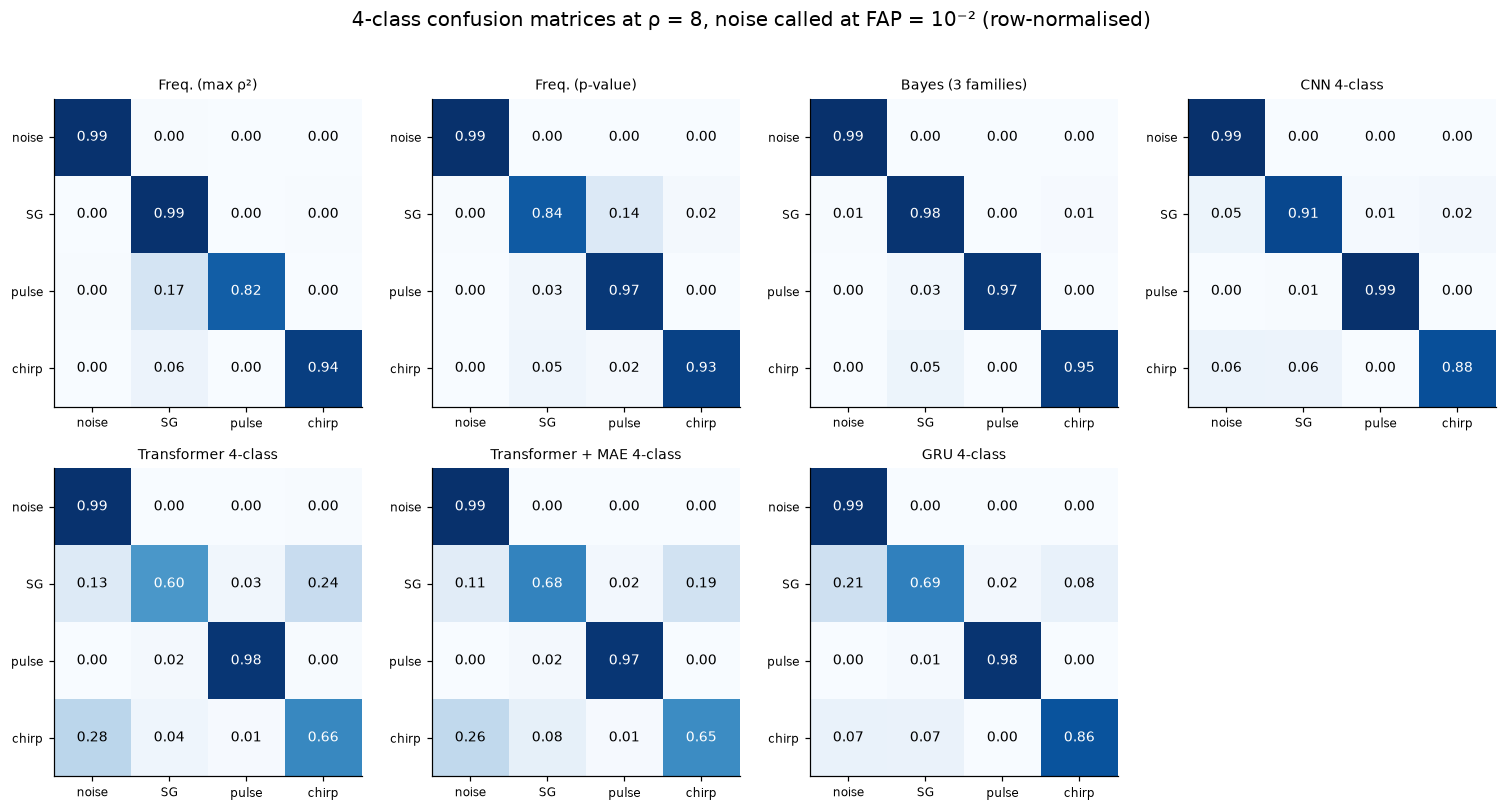

In [15]:
# confusion matrices at rho = 8 (rows: truth, columns: decision; noise row from the test noise windows)
SNR_C = 8
fig, ax = plt.subplots(2, 4, figsize=(17, 8)); ax = ax.ravel(); conf = {}
for a, n in zip(ax, MC):
    C = np.zeros((4, 4))
    d0 = decide4(n, ST["test"]); C[0] = np.bincount(d0, minlength=4) / len(d0)
    for k in g.MORPHS:
        d = decide4(n, ST[(k, SNR_C)]); C[TRUE[k]] = np.bincount(d, minlength=4) / len(d)
    conf[n] = C.tolist(); a.imshow(C, vmin=0, vmax=1, cmap="Blues")
    for i in range(4):
        for j in range(4): a.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", color="white" if C[i, j] > .5 else "black", fontsize=9)
    a.set_xticks(range(4)); a.set_yticks(range(4)); a.set_xticklabels(["noise", "SG", "pulse", "chirp"], fontsize=8); a.set_yticklabels(["noise", "SG", "pulse", "chirp"], fontsize=8); a.set_title(n, fontsize=9); a.grid(False)
ax[-1].axis("off"); fig.suptitle(f"4-class confusion matrices at ρ = {SNR_C}, noise called at FAP = 10⁻² (row-normalised)")
g.savefig(fig, "fig06_confusion"); plt.show()
summary["confusion_rho8"] = conf

In [16]:
# overall 4-class accuracy on a balanced test set (noise windows = the test noise; signals = all test injections with SNR in 4..12), and ensembles vs single networks
rows = []
for n in MC + ["CNN 4-class (single)", "Transformer 4-class (single)", "Transformer + MAE 4-class (single)"]:
    for lo, hi in ((4, 7), (8, 16)):
        sel = [s for s in SNRS if lo <= s <= hi]
        ys = np.concatenate([np.full(NINJ, TRUE[k]) for k in g.MORPHS for s in sel]); ds = np.concatenate([decide4(n, ST[(k, s)]) for k in g.MORPHS for s in sel])
        d0 = decide4(n, ST["test"])
        rows.append(dict(method=n, snr_range=f"{lo}-{hi}", signal_class_accuracy=float((ds == ys).mean()), noise_correct=float((d0 == 0).mean()),
                         balanced_accuracy=float(0.5 * (ds == ys).mean() + 0.5 * (d0 == 0).mean()), missed=float((ds == 0).mean())))
bal = pd.DataFrame(rows); summary["accuracy_4class"] = rows
bal.pivot(index="method", columns="snr_range", values="balanced_accuracy").round(3).join(bal.pivot(index="method", columns="snr_range", values="missed").round(3), lsuffix=" bal.acc.", rsuffix=" missed")

snr_range,4-7 bal.acc.,8-16 bal.acc.,4-7 missed,8-16 missed
method,,,,
Bayes (3 families),0.778,0.988,0.402,0.000
CNN 4-class,0.722,0.983,0.507,0.009
CNN 4-class (single),0.696,0.976,0.557,0.013
Freq. (max ρ²),0.750,0.975,0.412,0.000
Freq. (p-value),0.773,0.925,0.401,0.000
GRU 4-class,0.700,0.966,0.538,0.030
Transformer + MAE 4-class,0.665,0.947,0.599,0.031
Transformer + MAE 4-class (single),0.657,0.939,0.614,0.040
Transformer 4-class,0.661,0.944,0.602,0.035


Which structure tells the morphology? Results (3-way accuracy among signals; "gated" = signals above the Bayesian detection threshold at FAP = 10⁻²):

* **Bayesian model comparison is the best classifier at every SNR above ≈ 6** (0.969 at ρ = 8, 0.977 at ρ = 10) and the best 4-class balanced accuracy at both SNR ranges (0.778 for ρ = 4–7, 0.988 for ρ = 8–16). The CNN 4-class network is close at high SNR (0.960 at ρ = 8, 0.980 at ρ = 10) and 0.04–0.05 behind at ρ = 5–6; the GRU is next (0.925 at ρ = 8), the Transformer last (0.867–0.873), pre-trained or not.
* **Frequentist model comparison depends on how the trial factors are handled.** Taking the family with the largest $\rho^2_f$ (0.921 at ρ = 8) is worse than the Bayes factor by 0.05; converting each $\rho^2_f$ into a background p-value is the best rule at ρ ≤ 5 (0.825 at ρ = 5) but its accuracy *falls* with the SNR beyond ρ ≈ 9 (0.82 at ρ = 14): the empirical p-values of loud signals saturate at $1/(N+1)$ for every family and the tie is broken by the raw $\rho^2$, which favours the families with more templates. This is a limit of the 8 000-window background, not a feature of the method.
* **Detection first, then morphology.** Only ≈ 46 % of the ρ = 5 injections and 97 % of those at ρ = 7 pass the gate, so the morphology can be discussed only for signals loud enough to be detected; among the 4–7 range the fraction of signals called noise is 0.40 (Bayes, Freq.), 0.51 (CNN), 0.54 (GRU), 0.60 (Transformer).
* The answer to the question of the project: among the networks the *convolutional* structure (local filters + global pooling) does best, a bidirectional recurrent encoder is the second and attention on 16-sample patches the third; none of them beats the Bayesian comparison, which uses the exact likelihood of each family, and the best network only matches it at high SNR. The advantage that a supervised network has — it learns the glitch-contaminated noise distribution — does not show up in the morphology task.

### A signal that is incompatible with every hypothesis

A Gaussian-enveloped burst of band-limited **stochastic** noise (σ_t = 15 ms, injected at ρ = 8 and 12 into the test noise windows) belongs to none of the three families. A supervised network has no "unknown" class; the Bayesian classifier has one only through the evidence ratio. For each method: the fraction of these bursts that pass the method's own detection threshold (FAP = 10⁻²) and which class they are given.

In [17]:
def stochastic_burst(v, snr, r, sigma=0.015):
    t = np.arange(g.NWIN) / g.FS; t0 = r.uniform(0.3, 0.7, (len(v), 1))
    w = r.normal(size=v.shape) * np.exp(-0.5 * ((t[None] - t0) / sigma) ** 2)
    X = g.to_bins(w); w = g.to_series(X * (snr / g.snr_of(X))[:, None]); return v + w
ro = np.random.default_rng(31); OOD = {}
idx = ro.choice(len(vte), 800, replace=False)
for snr in (8, 12): OOD[snr] = statistics(raw_all(stochastic_burst(vte[idx], snr, ro), cte[idx]))
rows = []
for snr in OOD:
    for n in MC:
        d = decide4(n, OOD[snr]); det = d > 0
        rows.append(dict(snr=snr, method=n, detected=float(det.mean()), **{f"called_{c}": float((d == i + 1).sum() / max(det.sum(), 1)) for i, c in enumerate(["SG", "pulse", "chirp"])}))
ood = pd.DataFrame(rows); summary["ood"] = rows
ood[ood.snr == 8].set_index("method").drop(columns="snr").round(2).join(ood[ood.snr == 12].set_index("method").drop(columns="snr").round(2), lsuffix=" (ρ=8)", rsuffix=" (ρ=12)")

,detected (ρ=8),called_SG (ρ=8),called_pulse (ρ=8),called_chirp (ρ=8),detected (ρ=12),called_SG (ρ=12),called_pulse (ρ=12),called_chirp (ρ=12)
method,,,,,,,,
Freq. (max ρ²),0.39,0.94,0.04,0.02,0.98,0.93,0.06,0.01
Freq. (p-value),0.35,0.70,0.29,0.01,0.98,0.59,0.40,0.00
Bayes (3 families),0.30,0.69,0.29,0.01,0.98,0.80,0.20,0.01
CNN 4-class,0.45,0.89,0.10,0.01,0.98,0.95,0.05,0.00
Transformer 4-class,0.36,0.60,0.27,0.13,0.96,0.82,0.16,0.02
Transformer + MAE 4-class,0.38,0.69,0.21,0.10,0.95,0.85,0.14,0.02
GRU 4-class,0.36,0.79,0.19,0.02,0.94,0.90,0.09,0.01


Every method *detects* the stochastic burst when it is loud (94–98 % at ρ = 12; 30–45 % at ρ = 8, the CNN being the most sensitive) and every method gives it a family, mostly **sine-Gaussian** (0.93 for max-ρ², 0.95 CNN, 0.80 Bayes, 0.82–0.85 Transformers, 0.90 GRU at ρ = 12) and next pulse (0.05–0.40). None of the methods has a way to say "none of the above": the softmax of a network is normalised over the classes it knows, the posterior of the Bayesian classifier over the families it contains. The 4-class output is therefore only meaningful for signals that belong to the hypotheses; flagging the others would need an explicit goodness-of-fit (for the matched filter: the residual after subtracting the best template, not tested here), or an open-set/outlier head on the network.

In [18]:
summary.update(chunks_split=g.SPLIT, epochs={k: [len(h["loss"]) for h in v] for k, v in HIST.items()}, n_background=dict(val=len(vte) if False else len(data["val"][0]), test=len(vte)))
g.save_json(summary, "06_summary.json"); print("saved:", list(summary))

saved: ['params', 'pretraining', 'label_efficiency', 'detection', 'glitches', 'attention_localisation', 'morphology_accuracy', 'confusion_rho8', 'accuracy_4class', 'ood', 'chunks_split', 'epochs', 'n_background']


## Output and next step

* `results/06_summary.json`, `figures/fig06_*`; trained models and the cached statistics in `cache/models/` and `cache/stats06.pkl` (not tracked, regenerated by re-running; the pre-trained encoder is `cache/models/mae_encoder.weights.h5`).

This closes the machine-learning extension of the project: the report in `Docs/report/` can now add the sequence-model and hypothesis-testing results to the comparison of the three approaches.